In [2]:
#Packages needed for the notebook
using CSV #to read CSV files
using Serialization #datasets are saved like .bin file
using Revise #To include julia files with functions needed to run the notebook
using LinearAlgebra #For linear algebra operations
using Random #To extract random numbers
using PyPlot #To plot results
using NaNStatistics #To make avareges over windows
using Statistics #For mean values 

### Including Files

In [3]:
function correct_path(splitted_path, String)
    S=""
    for i in 1:(length(splitted_path)-1)
        S=S*splitted_path[i]*"/"
    end
    return S*String 
end

correct_path (generic function with 1 method)

In [4]:
#Including files with the functions
includet(correct_path(split(pwd(), '/'), "Functions/Variables and Structures.jl")) #For constant quantities or structures to save data
includet(correct_path(split(pwd(), '/'), "Functions/Inference.jl")) #For Training
includet(correct_path(split(pwd(), '/'), "Functions/Model Strategies and Testing.jl")) #For scoring testing datasets
includet(correct_path(split(pwd(), '/'), "Functions/Performance Indicator.jl")) #To compute performance over test datasets

In [5]:
#Train,validation, prior from GLORI HEK293T 
#Importing, training, test and prior datasets
train=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Train_GLORI.bin")) 
validation=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Validation_GLORI.bin")) 
prior_HEK=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Prior_GLORI.bin")); 
"""Test sets for HEK293T"""
#Unaltered conditions
test_HEK=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HEK_CC_GLORI.bin")) 
#Altered conditions
test_HEK_FTO=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HEK_FTO_GLORI.bin")) 
test_HEK_STM2457=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HEK_STM2457_GLORI.bin")) 
"""Test sets for HeLa"""
#Unaltered conditions
test_HELA=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_CC.bin")) 
#Altered conditions
test_HELA_siMETTL3=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_siMETTL3_GLORI.bin")) 
test_HELA_siMETTL14=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_siMETTL14_GLORI.bin")) 
test_HELA_siYTDH=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_siYTHDF2_GLORI.bin")) 
test_HELA_HPX=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_Hypoxia_GLORI.bin")) 
test_HELA_STM2457=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_STM2457_GLORI.bin"));


In [6]:
#Saving all the gene labels for the train, validation and prior
gene_train=keys(train)
gene_valid=keys(validation)
gene_prior_HEK=keys(prior_HEK);
#Saving test genes from unaltered conditions in both HEK293T and HeLa
gene_test_HEK=keys(test_HEK);
gene_HELA=keys(test_HELA);

In [7]:
#Creating training sets of m6A and A
train_met, ratio_train , gene_train_met , train_not , gene_train_not =crete_set_all(train, gene_train);

### Prior definition

The prior follows the two definition, the constant and the transcript-dependent one, below defined:

$$p_0(m)= \frac{1}{\mathcal{N}_\mathcal{T}}\sum_{i=1}^{\mathcal{N}_\mathcal{T}} \frac{N^{T'_i}_{m^6A}}{N^{T'_i}_{m^6A}+N^{T'_i}_A}=\langle p_0^{T'}(m)\rangle_{T'}$$
 $$p_0^{T_j}(m)=\frac{\langle p_0^{T'}(m)\rangle_{T'}}{\langle p_0^{\tilde{T}}(m)\rangle_{\tilde{T}}}p_0^{\tilde{T}_j}(m) $$

where $T'$ corresponds to training genes, $p_0(m)$ the constant prior definition, and $\tilde{T}$ the set of genes from the prior dataset (replicate experiment).

In [8]:
#Constant prior definition following the previous equations
Ava=[] #Initialization for the constant prior
[push!(Ava, train[a].perc_met) for a in gene_train];
Ava=mean(Ava) #p_0(m)
#Initialization for the transcript dependent prior
P=[] 
[push!(P, prior_HEK[a].perc_met) for a in keys(prior_HEK)] #Needed for the computation of the constant prior over T̃
[prior_HEK[a].perc_met=Ava/mean(P).*prior_HEK[a].perc_met for a in keys(prior_HEK)]; #p_0^T(m)

### Training

In [9]:
#Importing models trained on GLORI HEK293T
M5=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_met.bin")) # p(s̄|m)
M6=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_not_met.bin")); # p(s̄|m̄)

### Distibution of motives (train-set):

In [10]:
#Computing distribution of m6A and A over transcripts
bin=collect(0:0.001:1);
avarege_window=20
x_met, y_met=avarege_distribution(train, gene_train, avarege_window, bin; label=1) #d(x(s̄_T |m))
x_not, y_not=avarege_distribution(train, gene_train, avarege_window, bin; label=0); #d(x(s̄_T |m̄))

### Test:

A common set of genes is taken, consindering all transcripts with at least one methylated site in the unaltered conditions (excluding training and validating ones). 

In [11]:
#Finding genes not in the training, nor the validating, set considering HEK293T
gene_HEK_not_train=[]
[(haskey(train, a)==false && haskey(validation, a)==false ? push!(gene_HEK_not_train, a) : nothing ) for a in gene_test_HEK];

In [12]:
#To test genes I only keep those transcripts for which a proxy of the methylation abundancy is knwon
common_genes_HEK=intersect(vcat(gene_prior_HEK...),vcat(gene_HEK_not_train...)) # T̃ ∩ T 
genes_not_HEK=filtering_non_nucelotides(test_HEK)
#Removing a gene with non canonical nucleotide letterse
common_genes_HEK=setdiff(common_genes_HEK, genes_not_HEK); # T̃ ∩ T \ T_n 

The gene IPMK contain a (some) non-nucleotide(s) character(s) at position(s) [26] corresponding to the chacracter(s): N 
The gene PLCL2 contain a (some) non-nucleotide(s) character(s) at position(s) [3518] corresponding to the chacracter(s): W 


In [13]:
#Finding genes not in the training, nor the validating, set considering HeLa
gene_HELA_not_train=[]
[(haskey(train, a)==false && haskey(validation, a)==false ? push!(gene_HELA_not_train, a) : nothing) for a in gene_HELA];

In [14]:
#To test genes I only keep those transcripts for which a proxy of the methylation abundancy is knwon
common_genes_HELA=intersect(vcat(gene_prior_HEK...),vcat(gene_HELA_not_train...)) # T̃ ∩ T 
genes_not_HELA=filtering_non_nucelotides(test_HELA)
#Removing a gene with non canonical nucleotide letterse
common_genes_HELA=setdiff(common_genes_HELA, genes_not_HELA); # T̃ ∩ T \ T_n 

The gene RNA45SN2 contain a (some) non-nucleotide(s) character(s) at position(s) [11220] corresponding to the chacracter(s): N 
The gene IPMK contain a (some) non-nucleotide(s) character(s) at position(s) [26] corresponding to the chacracter(s): N 
The gene PLCL2 contain a (some) non-nucleotide(s) character(s) at position(s) [3518] corresponding to the chacracter(s): W 


In [15]:
#HEK293T
Test_HEK_FTO=copy_common_only(common_genes_HEK, test_HEK_FTO, test_HEK);
Test_HEK_STM2457=copy_common_only(common_genes_HEK, test_HEK_STM2457, test_HEK);
#HeLa
Test_HELA_HPX=copy_common_only(common_genes_HELA, test_HELA_HPX,test_HELA);
Test_HELA_STM2457=copy_common_only(common_genes_HELA, test_HELA_STM2457,test_HELA;)
Test_HELA_siMETTL3=copy_common_only(common_genes_HELA, test_HELA_siMETTL3, test_HELA);
Test_HELA_siMETTL14=copy_common_only(common_genes_HELA, test_HELA_siMETTL14, test_HELA);
Test_HELA_siYTDH=copy_common_only(common_genes_HELA, test_HELA_siYTDH, test_HELA);

We divide the testing genes in three independent sets to compute averages and standard deviation.

In [16]:
sous_HEK=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/SousHEK.bin"));

In [17]:
sous_HELA=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/SousHELA.bin"));

### Mapping:

In [18]:
MAP_mRNA_HEK=mapping_position(test_HEK, vcat(common_genes_HEK...));
MAP_mRNA_HELA=mapping_position(test_HELA, vcat(common_genes_HELA...));

## MEMAR-XT

The model is defined following the equation: $$p(m|\vec{s}) \propto p(\vec{s}|m) \cdot d(x_T(\vec{s})|m)\cdot p_0^T(m)$$

In [18]:
Dict_DRACH=Dict()
[Dict_DRACH[a]=[]  for a in DRACH];

In [19]:
#Scoring genomes for HEK293T
score_HEK=[score_genome_complete(M5, M6, prior_HEK[a].perc_met/100, test_HEK[a].sequence, 8; verbose=true, Mapping=MAP_mRNA_HEK, dist_met=[x_met, y_met], dist_not=[x_not, y_not], bin=0.001, gene=a) for a in keys(MAP_mRNA_HEK)];
#Distinguishing between methylated and non-methylated sites based on the experimental detection
score_met_HEK,score_not_met_HEK=divide_score(score_HEK, vcat(keys(MAP_mRNA_HEK)...), test_HEK)
score_met_FTO,score_not_met_FTO=divide_score(score_HEK, vcat(keys(MAP_mRNA_HEK)...), Test_HEK_FTO)
score_met_HEK_STM2457,score_not_met_HEK_STM2457=divide_score(score_HEK, vcat(keys(MAP_mRNA_HEK)...), Test_HEK_STM2457)

(Any[Any[], Any[], Any[], Any[0.16890499957312538, 0.14245120074224385, 0.6880572395874703, 0.6090267090341597, 0.24808062773176637, 0.6271650938324915], Any[0.03494962533011708], Any[], Any[], Any[], Any[0.3868288711878388], Any[]  …  Any[], Any[], Any[], Any[], Any[], Any[0.007115879908066283, 4.202771460016161e-6], Any[], Any[], Any[0.14090446912973767, 0.39716443578461363], Any[]], Any[Any[4.150883399908972e-6, 4.709746203560647e-5, 4.870740309929066e-6, 1.8459227927937043e-5, 6.12921253101067e-6, 0.00033536758350774515, 5.295890955540701e-6, 1.4621255479725807e-5, 0.0020553016070064384, 0.12250187301932014  …  3.473010151898076e-6, 2.727030369603659e-7, 2.9789475411009896e-6, 0.0002250714046877936, 3.091427037950222e-7, 3.0727554171704595e-7, 8.310297226508537e-8, 0.00015645659250150993, 1.2572133419009966e-6, 0.0], Any[0.0, 0.0, 1.0595364889191939e-5, 1.4043684647877306e-5, 1.3280704399225733e-5, 0.0001840791744305034, 0.0006865626263523068, 0.001156764210700636, 4.35114832001235

In [20]:
#Scoring genomes for HeLa
score_HELA=[score_genome_complete(M5, M6, prior_HEK[a].perc_met/100, test_HELA[a].sequence, 8; verbose=true, Mapping=MAP_mRNA_HELA, dist_met=[x_met, y_met], dist_not=[x_not, y_not], bin=0.001, gene=a) for a in keys(MAP_mRNA_HELA)];
#Distinguishing between methylated and non-methylated sites based on the experimental detection
score_met_HELA,score_not_met_HELA=divide_score(score_HELA, vcat(keys(MAP_mRNA_HELA)...), test_HELA)
score_met_HPX,score_not_met_HPX=divide_score(score_HELA, vcat(keys(MAP_mRNA_HELA)...), Test_HELA_HPX)
score_met_STM2457,score_not_met_STM2457=divide_score(score_HELA, vcat(keys(MAP_mRNA_HELA)...), Test_HELA_STM2457)
score_met_siMETTL3,score_not_met_siMETTL3=divide_score(score_HELA, vcat(keys(MAP_mRNA_HELA)...), Test_HELA_siMETTL3)
score_met_siMETTL14,score_not_met_siMETTL14=divide_score(score_HELA, vcat(keys(MAP_mRNA_HELA)...), Test_HELA_siMETTL14)
score_met_siYTH,score_not_met_siYTH=divide_score(score_HELA, vcat(keys(MAP_mRNA_HELA)...), Test_HELA_siYTDH);

In [21]:
#HEK293T
imb_HEK,tre_HEK,A_HEK, F_HEK=score_ava(score_met_HEK, score_not_met_HEK, sous_HEK ; pass=0.01)
imb_FTO,tre_FTO,A_FTO, F_FTO=score_ava(score_met_FTO, score_not_met_FTO, sous_HEK ; pass=0.01)
imb_HEK_STM,tre_HEK_STM,A_HEK_STM, F_HEK_STM=score_ava(score_met_HEK_STM2457, score_not_met_HEK_STM2457, sous_HEK ; pass=0.01);
#HeLa
imb_HELA,tre_HELA, A_HELA, F_HELA=score_ava(score_met_HELA, score_not_met_HELA, sous_HELA ; pass=0.01)
imb_STM2457,tre_STM2457,A_STM2457, F_STM2457=score_ava(score_met_STM2457, score_not_met_STM2457, sous_HELA ; pass=0.01)
imb_HPX,tre_HPX,A_HPX, F_HPX=score_ava(score_met_HPX, score_not_met_HPX, sous_HELA ; pass=0.01)
imb_siMETTL3,tre_siMETTL3, A_siMETTL3, F_siMETTL3=score_ava(score_met_siMETTL3, score_not_met_siMETTL3, sous_HELA ; pass=0.01)
imb_siMETTL14,tre_siMETTL14, A_siMETTL14, F_siMETTL3=score_ava(score_met_siMETTL14, score_not_met_siMETTL14, sous_HELA ; pass=0.01)
imb_siYTDH,tre_siYTDH, A_siYTDH, F_siYTDH=score_ava(score_met_siYTH, score_not_met_siYTDH, sous_HELA ; pass=0.01);

UndefVarError: UndefVarError: `score_met_siYTH` not defined

In [22]:
#Scoring all DRACH motifs with MEMAR-C
S_D=score_DRACH(M5, M6, Dict_DRACH, Ava/100);
N=18 #Number of DRACH motifs
ind=sortperm(vcat(values(S_D)...), rev=true) #indexes ordering of DRACH motifs based on the model score (decreasing order)
mot5A=vcat(keys(S_D)...)[ind] #ordered DRACH motifs by decreasing order
MOT5=[mot5A[i][1:2]*"A"*mot5A[i][3:4] for i in 1:length(mot5A)]; #adding central adenosine to consider 5-mers

In [1]:
S_D

UndefVarError: UndefVarError: `S_D` not defined

In [23]:
mots_HEK=ava_dist_DRACH(test_HEK, MAP_mRNA_HEK, S_D, ind, sous_HEK)
mots_HEK_STM=ava_dist_DRACH(Test_HEK_STM2457, MAP_mRNA_HEK, S_D, ind, sous_HEK)
mots_FTO=ava_dist_DRACH(Test_HEK_FTO, MAP_mRNA_HEK, S_D, ind, sous_HEK)

mots_HELA=ava_dist_DRACH(test_HELA, MAP_mRNA_HELA, S_D, ind, sous_HELA)
mots_siMETTL3=ava_dist_DRACH(Test_HELA_siMETTL3, MAP_mRNA_HELA, S_D, ind, sous_HELA)
mots_YTH=ava_dist_DRACH(Test_HELA_siYTDH, MAP_mRNA_HELA, S_D, ind, sous_HELA)
mots_siMETTL14=ava_dist_DRACH(Test_HELA_siMETTL14, MAP_mRNA_HELA, S_D, ind, sous_HELA)
mots_HPX=ava_dist_DRACH(Test_HELA_HPX, MAP_mRNA_HELA, S_D, ind, sous_HELA)
mots_HELA_STM=ava_dist_DRACH(Test_HELA_STM2457, MAP_mRNA_HELA, S_D, ind, sous_HELA);

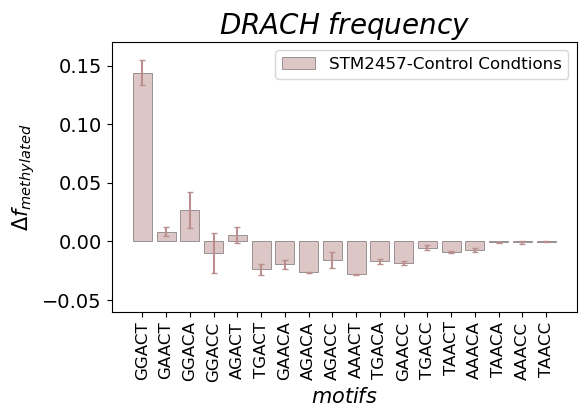

In [24]:
stat_plot(mots_HELA_STM, mots_HELA, "STM2457-Control Condtions", (6, 3.5), "rosybrown")

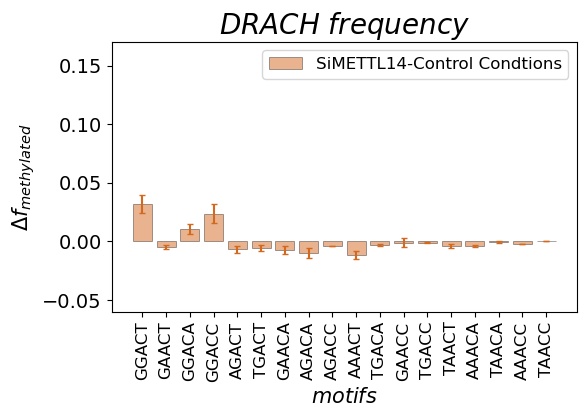

In [25]:
stat_plot(mots_siMETTL14, mots_HELA, "SiMETTL14-Control Condtions", (6, 3.5), "chocolate")

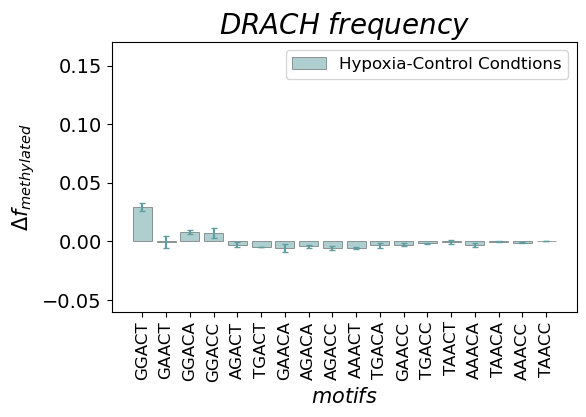

In [26]:
stat_plot(mots_HPX, mots_HELA, "Hypoxia-Control Condtions", (6, 3.5), "cadetblue")

### Transcript-dependent Module


In [27]:
#HEK293T
S_HEK=Dict()
[S_HEK[label]=score_genome_complete(M5, M6, prior_HEK[label].perc_met/100, test_HEK[label].sequence, 8;  verbose=true, Mapping=MAP_mRNA_HEK, dist_met=[x_met, y_met], dist_not=[x_not, y_not], gene=label) for label in keys(MAP_mRNA_HEK)];
#HeLa
S_HELA=Dict()
[S_HELA[label]=score_genome_complete(M5, M6, prior_HEK[label].perc_met/100, test_HELA[label].sequence, 8;  verbose=true, Mapping=MAP_mRNA_HELA, dist_met=[x_met, y_met], dist_not=[x_not, y_not], gene=label) for label in keys(MAP_mRNA_HELA)];

In [37]:
HEK, pp_HEK, dist_HEK=stat_m6A(MAP_mRNA_HEK, test_HEK, tre_HEK,S_HEK, sous_HEK)
HEK_STM, pp_HEK_STM, dist_HEK_STM=stat_m6A(MAP_mRNA_HEK, Test_HEK_STM2457, tre_HEK_STM,S_HEK, sous_HEK)
FTO, pp_FTO, dist_FTO=stat_m6A(MAP_mRNA_HEK, Test_HEK_FTO, tre_FTO,S_HEK, sous_HEK)

HELA, pp_HELA, dist_HELA=stat_m6A(MAP_mRNA_HELA, test_HELA, tre_HELA,S_HELA, sous_HELA)
siMETTL3,pp_siMETTL3, dist_siMETTL3=stat_m6A(MAP_mRNA_HELA, Test_HELA_siMETTL3, (tre_siMETTL3), S_HELA,sous_HELA)
HPX,pp_HPX,dist_HPX=stat_m6A(MAP_mRNA_HELA, Test_HELA_HPX, tre_HPX,S_HELA,sous_HELA)
siMETTL14,pp_siMETTL14, dist_siMETTL14=stat_m6A(MAP_mRNA_HELA, Test_HELA_siMETTL14, (tre_siMETTL14), S_HELA,sous_HELA)
siYTH,pp_siYTH, dist_siYTH=stat_m6A(MAP_mRNA_HELA, Test_HELA_siYTDH, (tre_siYTDH), S_HELA,sous_HELA)
siSTM,pp_siSTM, dist_siSTM=stat_m6A(MAP_mRNA_HELA, Test_HELA_STM2457, (tre_STM2457), S_HELA,sous_HELA)

(Any[Any[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 7.2727272727272725, 0.0  …  0.0, 5.607476635514018, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 2.083333333333333, 0.7194244604316548], Any[0.8, 0.6329113924050633, 3.7735849056603774, 6.315789473684211, 0.3067484662576687, 1.9553072625698324, 0.0, 0.0, 0.0, 0.0  …  2.3255813953488373, 2.4096385542168677, 0.2597402597402597, 0.0, 0.0, 1.7543859649122806, 0.0, 2.1739130434782608, 2.2857142857142856, 0.0], Any[1.098901098901099, 0.0, 0.0, 0.0, 4.819277108433735, 0.0, 0.0, 6.493506493506493, 0.0, 0.0  …  0.7843137254901961, 0.0, 0.0, 0.0, 0.0, 0.819672131147541, 0.0, 0.0, 0.0, 0.0]], Any[Any[3.7593984962406015, 0.0, 0.9345794392523363, 0.0, 0.0, 0.0, 0.0, 0.0, 7.2727272727272725, 0.0  …  0.0, 0.0, 0.0, 6.666666666666667, 0.0, 4.761904761904762, 0.48543689320388345, 0.0, 8.333333333333332, 0.0], Any[0.0, 0.0, 0.0, 4.2105263157894735, 0.3067484662576687, 0.5586592178770949, 0.0, 5.263157894736842, 0.0, 0.0  …  2.3255813953488373, 0.0, 0.5194805194805194, 0

In [38]:
#binning for the density different of the percentage of methylated DRACH motifs between prediction and experimental sites
binning_R=vcat(0:1:100...);

In [39]:
#HEK293T
dd_HEK=average_density_difference(pp_HEK,HEK, 3, binning_R)
dd_HEK_STM=average_density_difference(pp_HEK_STM,HEK_STM, 3, binning_R)
dd_FTO=average_density_difference(pp_FTO,FTO, 3, binning_R);
#HeLa
dd_HELA=average_density_difference(pp_HELA,HELA, 3, binning_R)
dd_HPX=average_density_difference(pp_HPX,HPX, 3, binning_R)
dd_siMETTL3=average_density_difference(pp_siMETTL3,siMETTL3, 3, binning_R);
dd_siMETTL14=average_density_difference(pp_siMETTL14,siMETTL14, 3, binning_R);
dd_siYTH=average_density_difference(pp_siYTH,siYTH, 3, binning_R);
dd_siSTM=average_density_difference(pp_siSTM,siSTM, 3, binning_R);


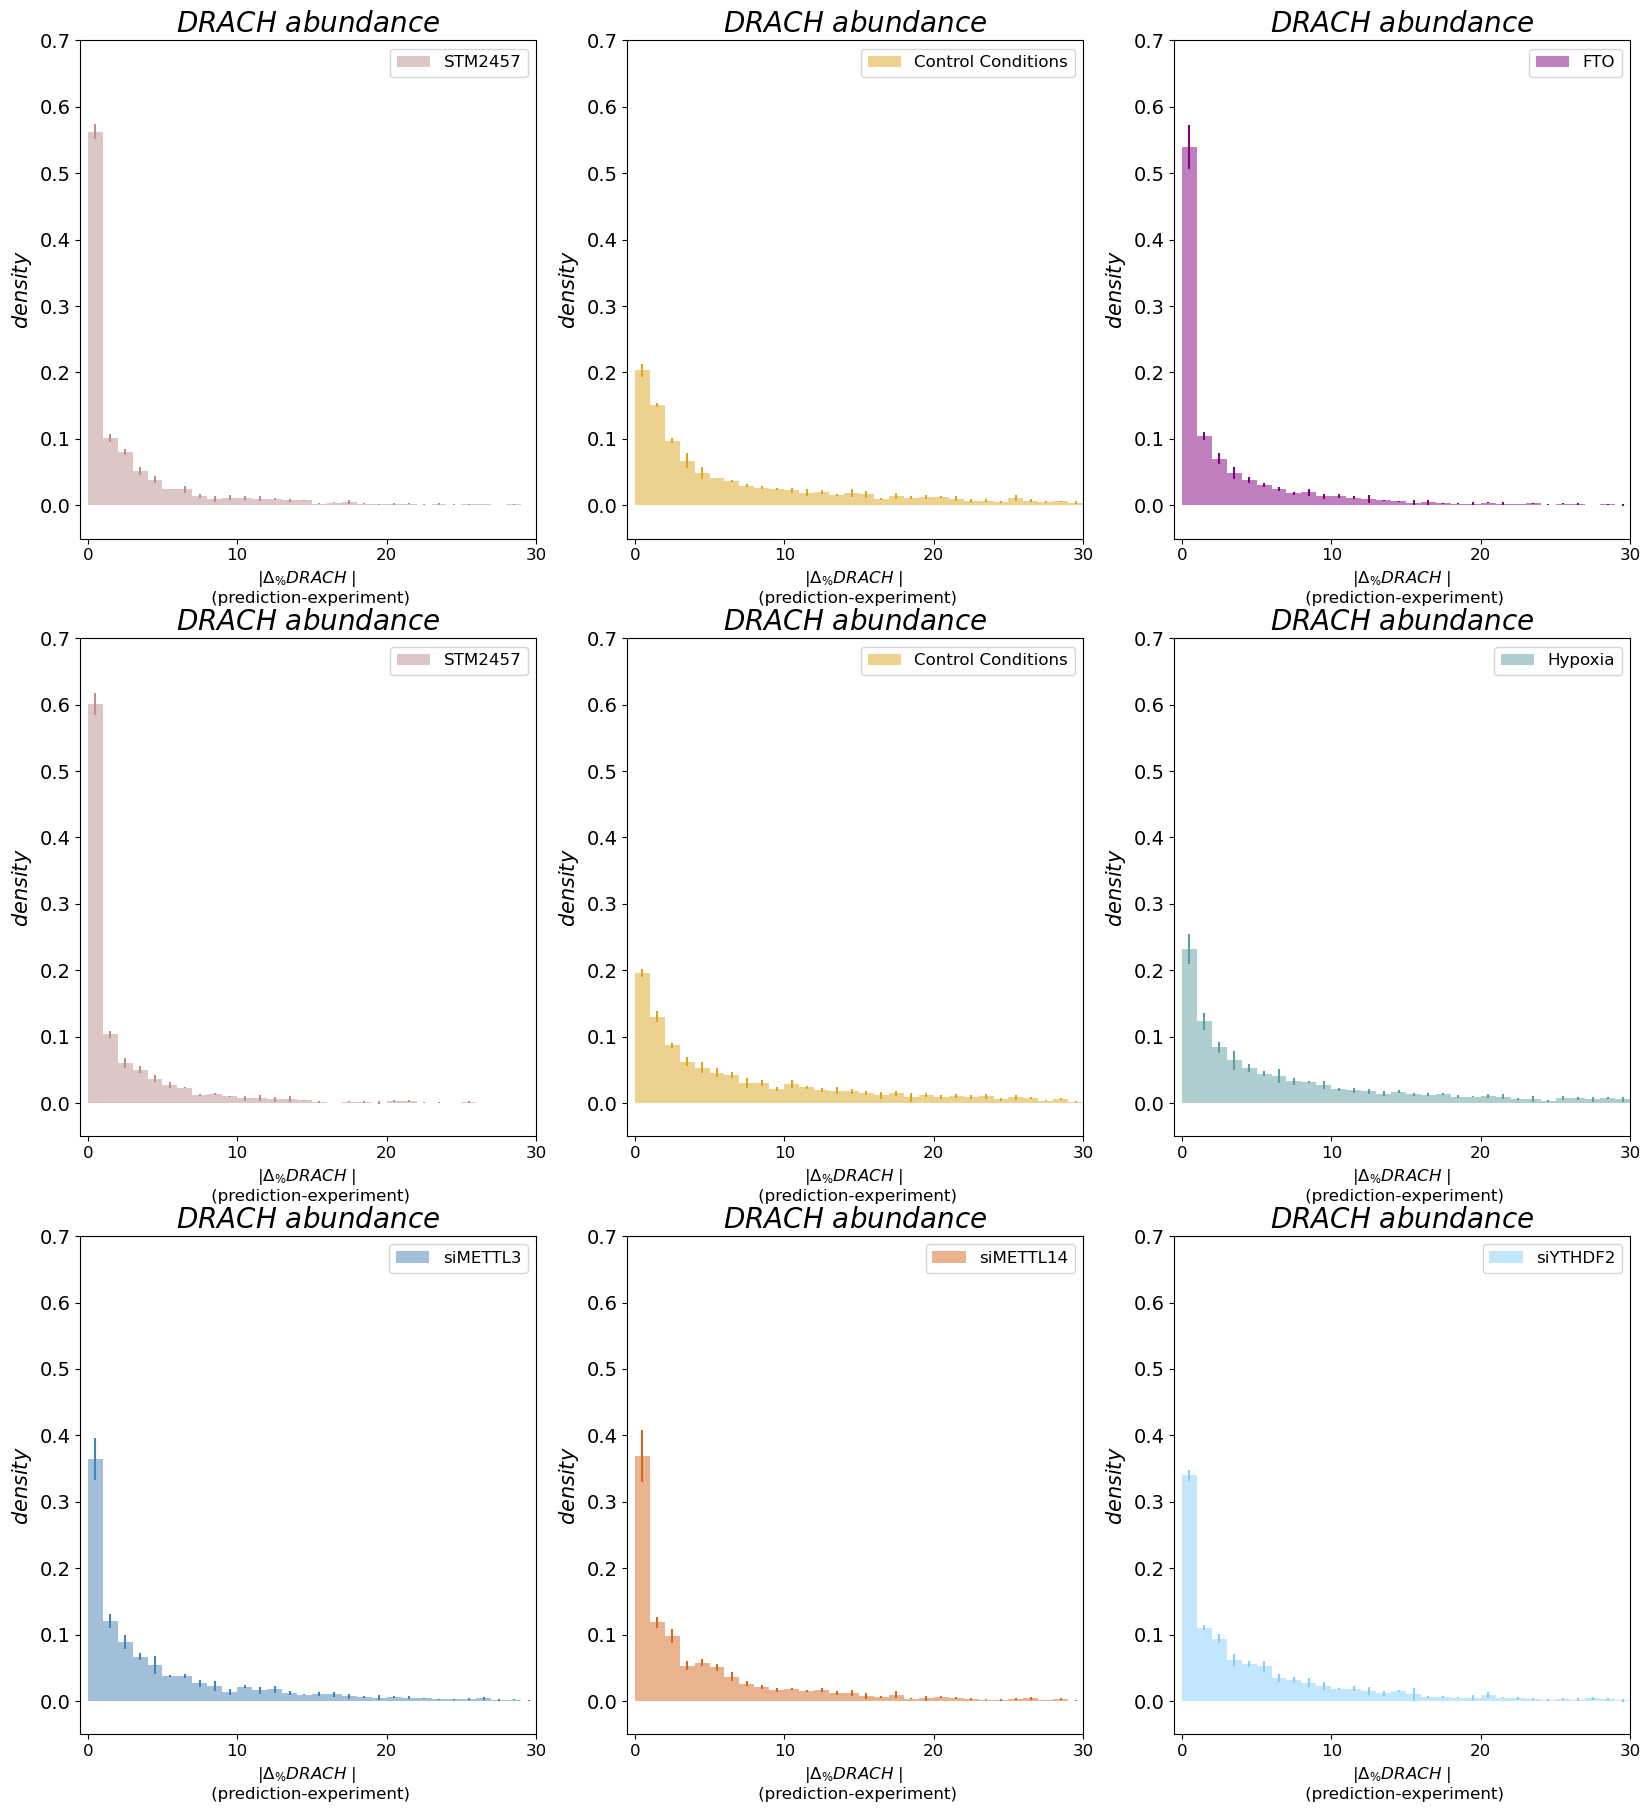

In [42]:
close("all")
figure(figsize=(20, 22))
subplot(3, 3,1)
plot_dens_diff(binning_R, "rosybrown", "STM2457", dd_HEK_STM, y_max=0.7)
subplot(3, 3,2)
plot_dens_diff(binning_R, "goldenrod", "Control Conditions", dd_HEK;y_max=0.7)
subplot(3, 3,3)
plot_dens_diff(binning_R, "purple", "FTO", dd_FTO, y_max=0.7)
subplot(3, 3,4)
plot_dens_diff(binning_R, "rosybrown", "STM2457", dd_siSTM, y_max=0.7)
subplot(3, 3,5)
plot_dens_diff(binning_R, "goldenrod", "Control Conditions", dd_HELA, y_max=0.7)
subplot(3, 3,6)
plot_dens_diff(binning_R, "cadetblue", "Hypoxia", dd_HPX, y_max=0.7)
subplot(3, 3,7)
plot_dens_diff(binning_R, "steelblue", "siMETTL3", dd_siMETTL3, y_max=0.7)
subplot(3, 3,8)
plot_dens_diff(binning_R, "chocolate", "siMETTL14", dd_siMETTL14, y_max=0.7)
subplot(3, 3,9)
plot_dens_diff(binning_R, "lightskyblue", "siYTHDF2", dd_siYTH, y_max=0.7)

### Position-Dependent Module

In [43]:
#HEK293T
x_met_HEK, y_met_HEK=ava_avarege_distribution(test_HEK, MAP_mRNA_HEK, avarege_window, bin, sous_HEK)
_, y_met_FTO=ava_avarege_distribution(Test_HEK_FTO, MAP_mRNA_HEK, avarege_window, bin, sous_HEK)
_, y_met_HEK_STM=ava_avarege_distribution(Test_HEK_STM2457, MAP_mRNA_HEK, avarege_window, bin, sous_HEK)
#HeLa
x_met_HELA, y_met_HELA=ava_avarege_distribution(test_HELA, MAP_mRNA_HELA, avarege_window, bin, sous_HELA)
_, y_met_HELA=ava_avarege_distribution(test_HELA, MAP_mRNA_HELA, avarege_window, bin, sous_HELA)
_, y_met_HPX=ava_avarege_distribution(Test_HELA_HPX, MAP_mRNA_HELA, avarege_window, bin, sous_HELA)
_, y_met_siMETTL3=ava_avarege_distribution(Test_HELA_siMETTL3, MAP_mRNA_HELA, avarege_window, bin, sous_HELA);
_, y_met_STM=ava_avarege_distribution(Test_HELA_STM2457, MAP_mRNA_HELA, avarege_window, bin, sous_HELA)
_, y_met_siYTDH=ava_avarege_distribution(Test_HELA_siYTDH, MAP_mRNA_HELA, avarege_window, bin, sous_HELA)
_, y_met_siMETTL14=ava_avarege_distribution(Test_HELA_siMETTL14, MAP_mRNA_HELA, avarege_window, bin, sous_HELA);

In [44]:
#HEK293T
d_HEK=average_dist_local(dist_HEK,3, bin);
d_HEK_STM=average_dist_local(dist_HEK_STM,3, bin);
d_FTO=average_dist_local(dist_FTO,3, bin);
#HeLa
d_HELA=average_dist_local(dist_HELA,3, bin);
d_HPX=average_dist_local(dist_HPX,3, bin);
d_siMETTL3=average_dist_local(dist_siMETTL3,3, bin);
d_STM=average_dist_local(dist_siSTM,3, bin);
d_siMETTL14=average_dist_local(dist_siMETTL14,3, bin);
d_siYTDH=average_dist_local(dist_siYTH,3, bin);

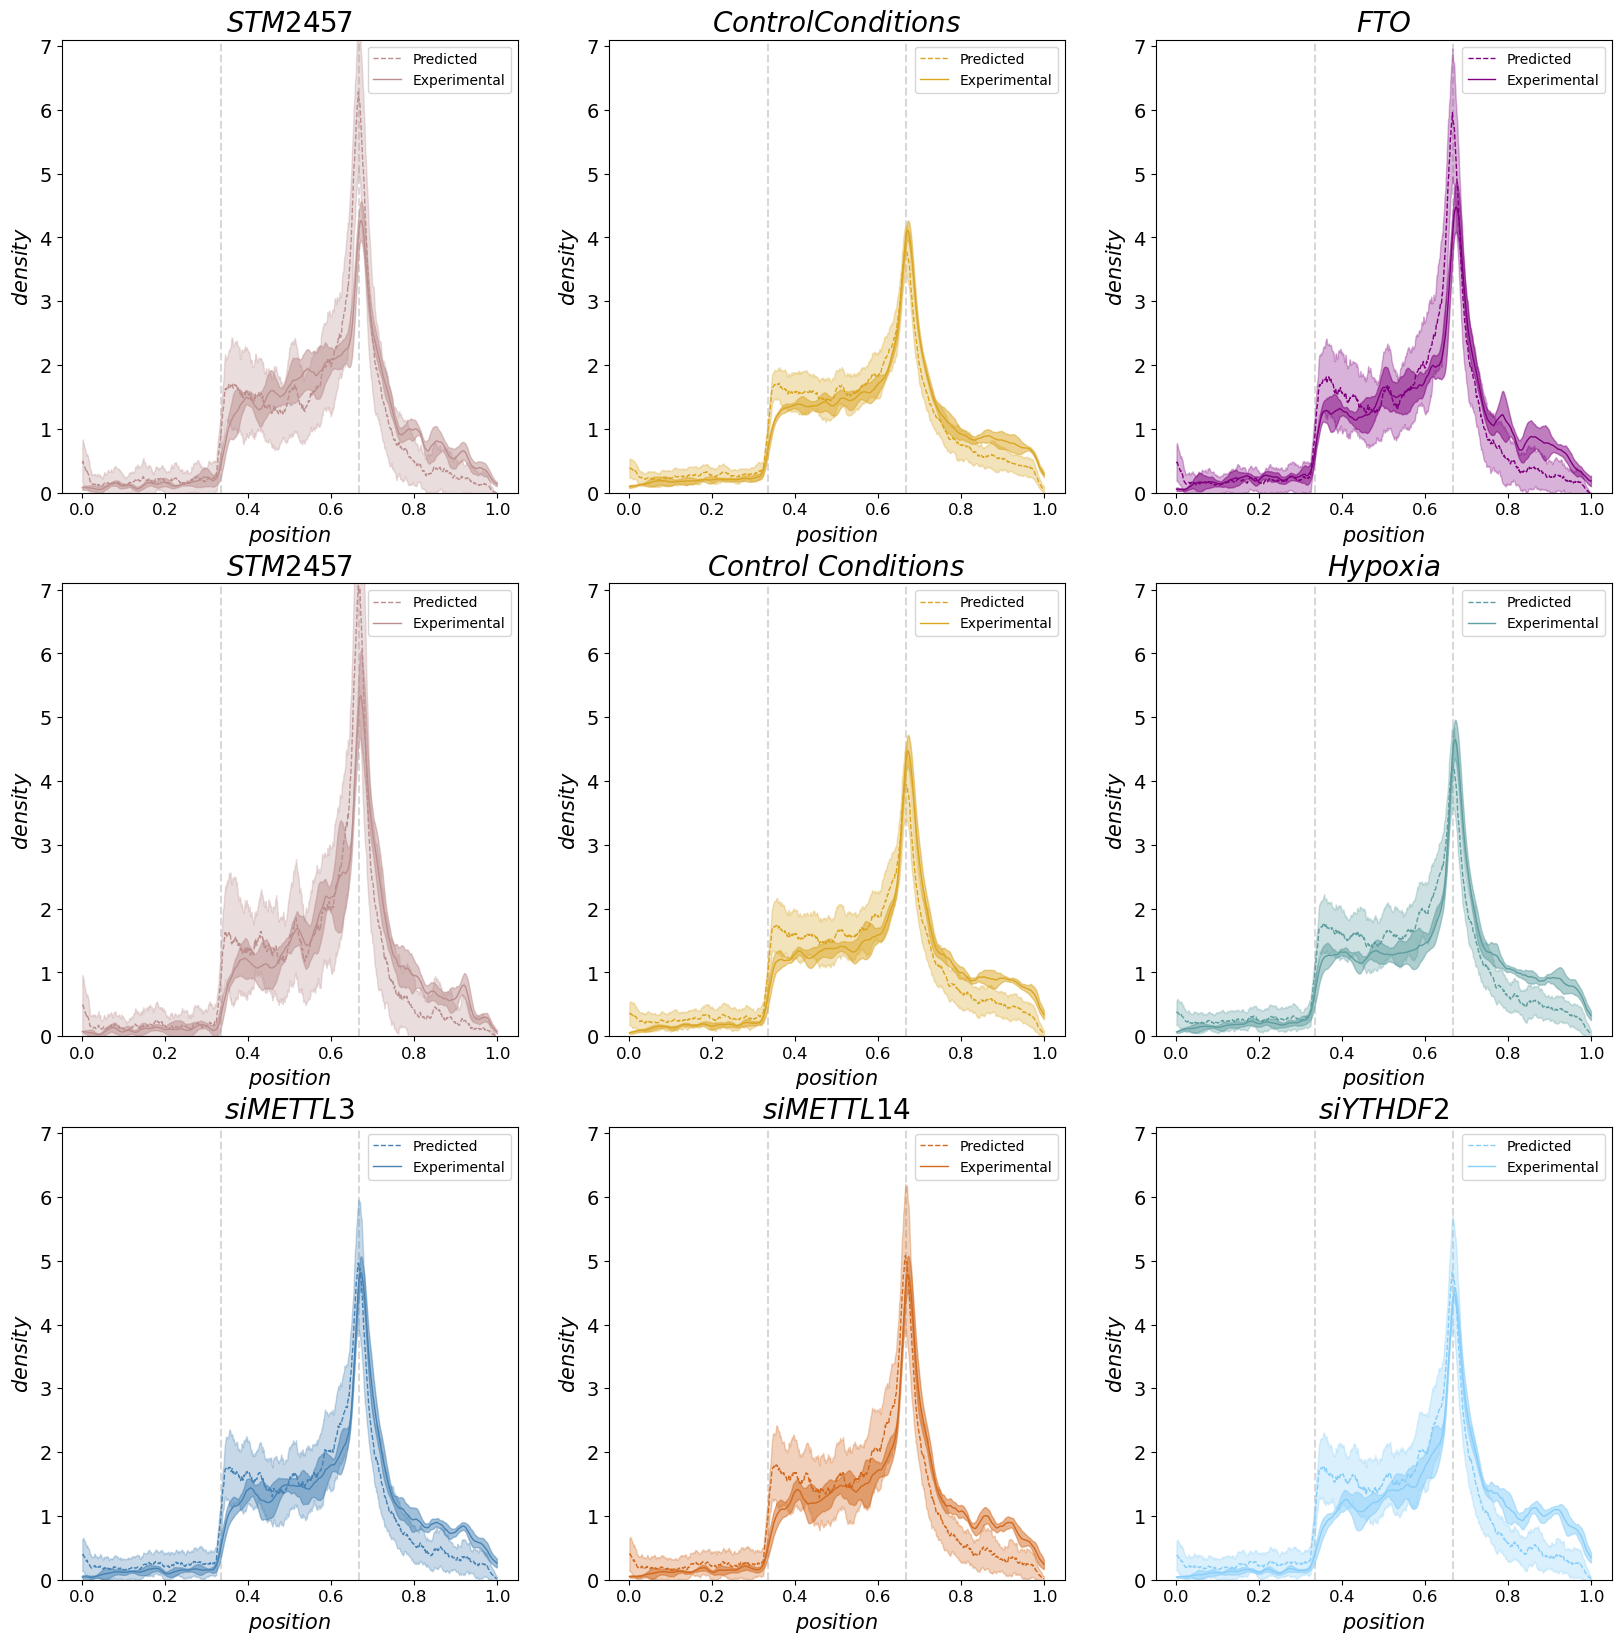

In [45]:
close("all")
figure(figsize=(20, 20))
subplot(3, 3,1)
title(L"STM2457", size=20)
plot_local(d_HEK_STM, y_met_HEK_STM,x_met_HEK, "rosybrown")
subplot(3, 3,2)
title(L"Control Conditions", size=20)
plot_local(d_HEK, y_met_HEK, x_met_HEK,"goldenrod")
subplot(3, 3,3)
title(L"FTO", size=20)
plot_local(d_FTO, y_met_FTO,x_met_HEK, "purple")
subplot(3, 3,4)
plot_local(d_STM, y_met_STM,x_met_HELA, "rosybrown";)
title(L"STM2457", size=20)
subplot(3, 3,5)
plot_local(d_HELA, y_met_HELA,x_met_HEK, "goldenrod")
title(L" Control \ Conditions", size=20)
subplot(3, 3,6)
plot_local(d_HPX, y_met_HPX, x_met_HEK,"cadetblue")
title(L"Hypoxia", size=20)
subplot(3, 3,7)
plot_local(d_siMETTL3, y_met_siMETTL3,x_met_HEK,"steelblue")
title(L" siMETTL3", size=20)
subplot(3, 3,8)
plot_local(d_siMETTL14, y_met_siMETTL14,x_met_HELA, "chocolate")
title(L"siMETTL14", size=20)
subplot(3, 3,9)
plot_local(d_siYTDH, y_met_siYTDH,x_met_HELA, "lightskyblue")
title(L"siYTHDF2", size=20)
gcf()